# 03 - Variant analysis

A **variant** is the exact sequence of steps one patient went through. Counting variants shows which pathways are common and which are rare.

Two levels are compared:
- **Exact:** every event, including repeated lab tests.
- **Milestone:** lab tests removed and repeats collapsed, leaving only the clinical steps (registration, triage, IV treatment, admission, release, return).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
sys.path.append(str(Path.cwd().parent / 'src'))

from plot_style import apply_style, save_fig, BLUE, INK, INK_SECONDARY
from prepare_log import load_events, load_cases
from variants import add_milestone_variant, variant_table, coverage, summary, shorten, SEPARATOR

apply_style()
ORANGE = '#eb6834'  # second categorical colour, used only to tell the two levels apart

events, cases = load_events(), load_cases()
cases = add_milestone_variant(events, cases)
exact = variant_table(cases, 'variant')
milestone = variant_table(cases, 'milestone_variant')
len(cases)

995

## 1. Headline numbers

In [2]:
pd.DataFrame({'Exact': summary(exact), 'Milestone': summary(milestone)}).round(1).rename(index={
    'variants': 'Distinct variants',
    'seen_once': 'Variants seen only once',
    'cases_in_unique_variants_pct': '% of cases in a one-off variant',
    'top10_coverage_pct': '% of cases covered by the top 10',
})

,Exact,Milestone
Distinct variants,619.0,96.0
Variants seen only once,539.0,44.0
% of cases in a one-off variant,54.2,4.4
% of cases covered by the top 10,22.2,73.5


## 2. How much do the top variants cover?
Cumulative share of patients covered as more variants are included. A steep curve means a few pathways describe most patients.

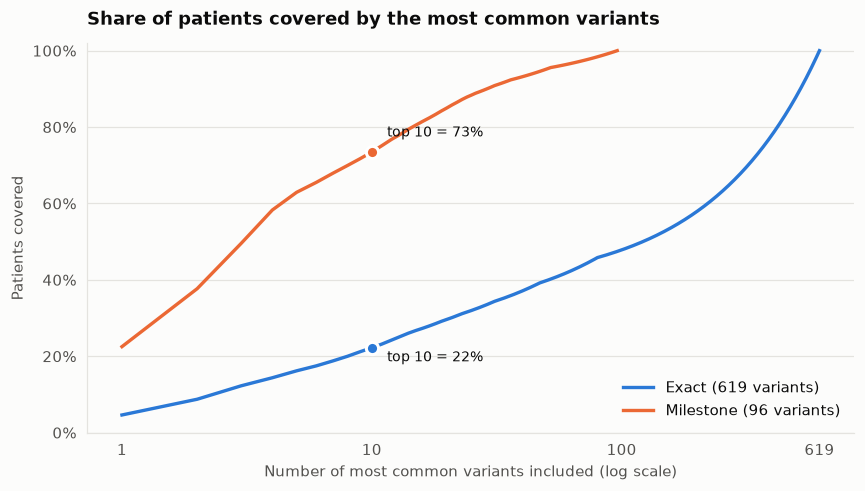

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for table, color, label in ((exact, BLUE, 'Exact'), (milestone, ORANGE, 'Milestone')):
    x = np.arange(1, len(table) + 1)
    ax.plot(x, table['cumulative_pct'], color=color, linewidth=2.2, label=f'{label} ({len(table)} variants)')
    ax.plot([10], [table['cumulative_pct'].iloc[9]], 'o', color=color, markersize=8, markeredgecolor='white', markeredgewidth=2)
    ax.annotate(f"top 10 = {table['cumulative_pct'].iloc[9]:.0f}%", (10, table['cumulative_pct'].iloc[9]),
                xytext=(10, -2 if label == 'Exact' else 8), textcoords='offset points', color=INK, fontsize=9,
                ha='left', va='top' if label == 'Exact' else 'bottom')
ax.set_xscale('log')
ax.set_xticks([1, 10, 100, len(exact)])
ax.set_xticklabels(['1', '10', '100', str(len(exact))])
ax.minorticks_off()
ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.grid(axis='x', visible=False)
ax.set_title('Share of patients covered by the most common variants')
ax.set_xlabel('Number of most common variants included (log scale)')
ax.set_ylabel('Patients covered')
ax.legend(loc='lower right', frameon=False)
save_fig(fig, 'variants_coverage')
plt.show()

## 3. Top 10 milestone pathways
The clinical pathway with lab tests left out.

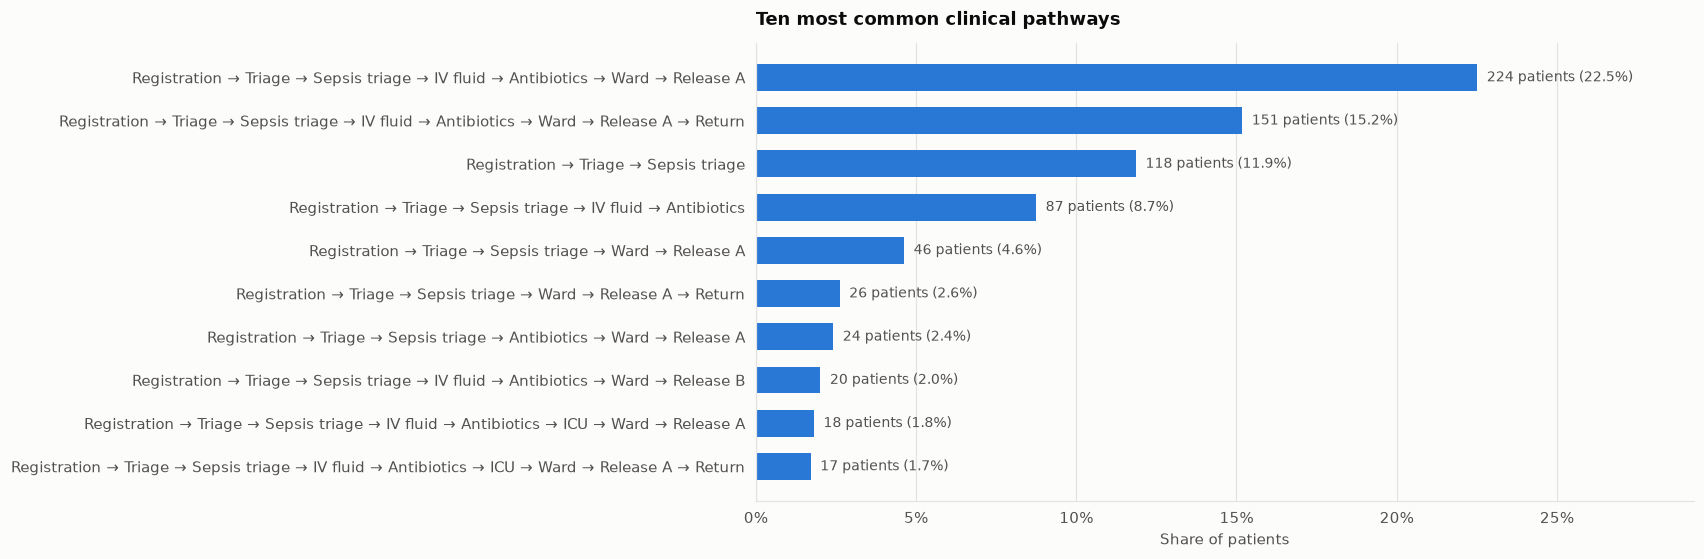

In [4]:
top = milestone.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.barh([shorten(v) for v in top['variant']], top['share_pct'], color=BLUE, height=0.62)
ax.grid(axis='y', visible=False)
for i, (n, share) in enumerate(zip(top['cases'], top['share_pct'])):
    ax.text(share + 0.3, i, f'{n} patients ({share:.1f}%)', va='center', color=INK_SECONDARY, fontsize=9)
ax.set_xlim(0, top['share_pct'].max() * 1.3)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Ten most common clinical pathways')
ax.set_xlabel('Share of patients')
save_fig(fig, 'variants_top_milestone')
plt.show()

In [5]:
milestone.head(10)[['rank', 'variant', 'cases', 'share_pct', 'cumulative_pct', 'median_duration_days']].round(1)

,rank,variant,cases,share_pct,cumulative_pct,median_duration_days
0,1,ER Registration > ER Triage > ER Sepsis Triage...,224,22.5,22.5,5.1
1,2,ER Registration > ER Triage > ER Sepsis Triage...,151,15.2,37.7,45.9
2,3,ER Registration > ER Triage > ER Sepsis Triage,118,11.9,49.5,0.0
3,4,ER Registration > ER Triage > ER Sepsis Triage...,87,8.7,58.3,0.1
4,5,ER Registration > ER Triage > ER Sepsis Triage...,46,4.6,62.9,3.8
5,6,ER Registration > ER Triage > ER Sepsis Triage...,26,2.6,65.5,61.4
6,7,ER Registration > ER Triage > ER Sepsis Triage...,24,2.4,67.9,4.3
7,8,ER Registration > ER Triage > ER Sepsis Triage...,20,2.0,69.9,6.0
8,9,ER Registration > ER Triage > ER Sepsis Triage...,18,1.8,71.8,6.3
9,10,ER Registration > ER Triage > ER Sepsis Triage...,17,1.7,73.5,82.5


## 4. How long does each pathway take?
Median case duration for the eight most common milestone pathways.

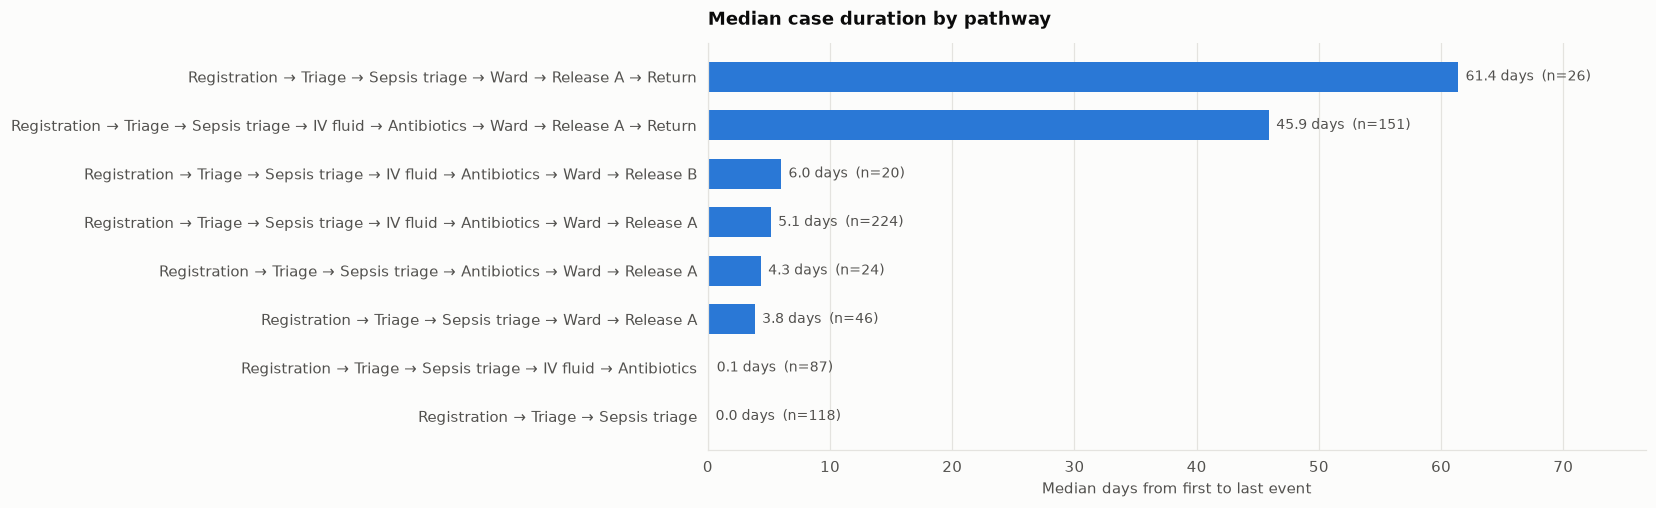

In [6]:
top8 = milestone.head(8).sort_values('median_duration_days')
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh([shorten(v) for v in top8['variant']], top8['median_duration_days'], color=BLUE, height=0.62)
ax.grid(axis='y', visible=False)
for i, (days, n) in enumerate(zip(top8['median_duration_days'], top8['cases'])):
    ax.text(days + top8['median_duration_days'].max() * 0.01, i, f'{days:.1f} days  (n={n})', va='center', color=INK_SECONDARY, fontsize=9)
ax.set_xlim(0, top8['median_duration_days'].max() * 1.25)
ax.set_title('Median case duration by pathway')
ax.set_xlabel('Median days from first to last event')
save_fig(fig, 'variants_duration')
plt.show()

## 5. Why the exact variants are so scattered
The ten most common exact pathways. They differ mostly in how many times the lab tests repeat.

In [7]:
pd.set_option('display.max_colwidth', 200)
exact.head(10)[['rank', 'variant', 'cases', 'share_pct', 'median_duration_days']].round(2)

,rank,variant,cases,share_pct,median_duration_days
0,1,ER Registration > ER Triage > ER Sepsis Triage > Leucocytes > CRP,46,4.62,0.02
1,2,ER Registration > ER Triage > ER Sepsis Triage > Leucocytes > CRP > LacticAcid > IV Liquid > IV Antibiotics,41,4.12,0.12
2,3,ER Registration > ER Triage > ER Sepsis Triage,35,3.52,0.01
3,4,ER Registration > ER Triage > ER Sepsis Triage > Leucocytes > CRP > LacticAcid,21,2.11,0.02
4,5,ER Registration > ER Triage > ER Sepsis Triage > Leucocytes > CRP > LacticAcid > IV Liquid > IV Antibiotics > Admission NC > Leucocytes > CRP > Release A,18,1.81,3.53
5,6,ER Registration > ER Triage > ER Sepsis Triage > Leucocytes > CRP > LacticAcid > IV Liquid > IV Antibiotics > Admission NC > Leucocytes > CRP > Leucocytes > CRP > Release A,13,1.31,5.49
6,7,ER Registration > ER Triage > ER Sepsis Triage > Leucocytes > CRP > LacticAcid > IV Liquid > IV Antibiotics > Admission NC > Release A,13,1.31,2.96
7,8,ER Registration > ER Triage > ER Sepsis Triage > Leucocytes > CRP > LacticAcid > IV Liquid > IV Antibiotics > Admission NC > Leucocytes > CRP > Release A > Return ER,12,1.21,43.93
8,9,ER Registration > ER Triage > Leucocytes > CRP > LacticAcid > ER Sepsis Triage > IV Liquid > IV Antibiotics,12,1.21,0.10
9,10,ER Registration > ER Triage > ER Sepsis Triage > IV Liquid > IV Antibiotics > Leucocytes > CRP > LacticAcid,10,1.01,0.02


In [8]:
# Same milestone pathway, different exact pathways: how many exact variants hide behind the most common one?
top_ms = milestone['variant'].iloc[0]
hidden = cases.loc[cases['milestone_variant'] == top_ms, 'variant'].nunique()
print(f'Most common milestone pathway: {shorten(top_ms)}')
print(f'{milestone["cases"].iloc[0]} patients, but {hidden} different exact variants (differences are repeated lab tests).')

Most common milestone pathway: Registration → Triage → Sepsis triage → IV fluid → Antibiotics → Ward → Release A
224 patients, but 135 different exact variants (differences are repeated lab tests).


## Findings
- **Exact pathways are very scattered.** The 995 patients follow 619 different exact pathways. 539 of them occur only once, so 54% of patients followed a pathway nobody else did. The 10 most common cover only 22% of patients.
- **The cause is repeated lab tests, not different care.** The most common clinical pathway has 224 patients, yet it appears as 135 different exact variants, which differ only in how often Leucocytes and CRP were repeated.
- **At the milestone level the picture is clear.** There are 96 pathways, only 4% of patients are in a one-off pathway, and the top 10 cover 73.5% of patients.
- **The standard pathway:** Registration, Triage, Sepsis triage, IV fluid, Antibiotics, Ward, Release A. It is followed by 22.5% of patients (224). Another 15.2% (151) follow the same path and then return to the ER, so 37.7% of patients share this route up to discharge.
- **Many patients have no recorded treatment or ending:** 11.9% (118) stop after Sepsis triage, and 8.7% (87) receive IV fluid and antibiotics but have no admission or release recorded. All 205 of these are among the 256 cases with no `Release` event, so most of the missing endings are patients whose pathway stops early in the ER. The reason is not in the data and should be confirmed with the mentor.
- **Returns make cases much longer.** Pathways that end with a return to the ER have a median of 46 to 61 days, against 4 to 5 days for the same pathways without a return. Across all cases, the median is 54 days for patients who return and 3.5 days for those who do not. The case duration includes the weeks before the patient comes back, so this is the time to return, not treatment time.
- **Next steps:** draw these pathways as a process map (commit 8) and measure the waiting time between steps (commit 9).